# Denis' pipeline with my mask midline: old EOD ↔ video sync, best fixed offset, and the synch_fix / synch_fix_newest tables

Both silent-fish controls (only one fish can discharge, so % correct = % of EODs given to that fish). Denis' pipeline unchanged (no
refractory step, highest cosine similarity), all fish midlines from the ZEUS masks (`fish_midline_with_head`). Three runs:

| run | EOD table | video frame of the masks | from |
|---|---|---|---|
| **no offset** | old (`Data_1fish_…`, `Assigned_Data_3fish_…`) | `Frame` | `EODAssignment/analysis/social_electric_fish_runners/denis_offset_runner_all.py` (saved) |
| **best fixed offset** | old | `Frame − 5` (2-fish), `Frame − 4` (3-fish) | `EODAssignment/analysis/social_electric_fish_runners/denis_offset_runner_all.py` (saved) |
| **synch_fix** | `Assigned_Data_2fish_…_synch_fix.csv`, `Data_3fish_…_synch_fix.csv` | `Frame` of the new table | `EODAssignment/analysis/social_electric_fish_runners/denis_synch_fix_runner.py` |
| **synch_fix_newest** | `Data_2fish_…_synch_fix_newest.csv`, `Data_3fish_…_synch_fix_newest.csv` | `Frame` of the new table | `EODAssignment/analysis/social_electric_fish_runners/denis_synch_fix_runner.py --table synch_fix_newest` |

The best fixed offsets are the ones found earlier: −4 frames (−80 ms) for 3-fish from the full sweep of my model, −5 for 2-fish
from the 300-EOD sweep. Masks: `*_Shiv_tracking_final.pkl` (the same ZEUS masks as before, renamed).

**Groups: the same EODs for every run.** The newest tables are a re-detection (31 extra EODs in 2-fish, 15 swapped in 3-fish), so
each EOD of the old table is found in the new tables by its electrode traces (pairs 1 and 2), and every group below holds only EODs
present in all three tables, so n is the same for all four runs:
- **all EODs**;
- **good frames, old QC**: the EOD's old frame is in `good_frames_better_list.csv` (mask QC, SLEAP-good, every mask ≥ 0.8 × median
  length) — clean for the no-offset run;
- **clean good, newest QC**: the EOD's frame in the newest table passes the same three checks (`clean_good_frames_newest.py`,
  which reproduces `good_frames_better_list.csv` exactly from the old table) — clean for the synch_fix_newest run.

An EOD with no mask midline for some fish counts as wrong.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import binomtest

REC = {
    '2-fish': dict(res='results/eod_ground_truth', true='A', best=-5, label='2-fish (2024-02-13)',
                   old_src='data/2_fish_silent/Data_1fish_2024-02-13T14_33_21.csv',
                   new_src='data/2_fish_silent/Assigned_Data_2fish_2024-02-13T14_33_21_synch_fix.csv',
                   newest_src='data/2_fish_silent/Data_2fish_2024-02-13T14_33_21_synch_fix_newest.csv'),
    '3-fish': dict(res='results/eod_ground_truth_3fish', true='C', best=-4, label='3-fish (2024-10-15)',
                   old_src='data/3_fish_silent/Assigned_Data_3fish_2024-10-15T14_12_25.csv',
                   new_src='data/3_fish_silent/Data_3fish_2024-10-15T14_12_25_synch_fix.csv',
                   newest_src='data/3_fish_silent/Data_3fish_2024-10-15T14_12_25_synch_fix_newest.csv'),
}
FPS = 50

def wilson(k, n, z=1.96):
    p = k / n; c = (p + z**2 / (2 * n)) / (1 + z**2 / n); hw = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return 100 * (c - hw), 100 * (c + hw)

def trace_key(path):
    """One string per EOD from its pair-1 and pair-2 traces (to find the same EOD in the old and new tables)."""
    d = pd.read_csv(path, usecols=lambda c: c.startswith(('electrode_1_', 'electrode_2_')))
    cols = [c for c in d.columns if c.startswith(('electrode_1_', 'electrode_2_'))]
    return pd.Series(['|'.join(f'{v:.6e}' for v in r) for r in d[cols].to_numpy(float)])

R = {}
for name, c in REC.items():
    D = f"{c['res']}/conductivities/denis_mask_midline_offset"
    runs = {'no offset': pd.read_csv(f'{D}/denis_mask_midline_all_eods_offset0.csv'),
            f"best fixed offset ({c['best']:+d})": pd.read_csv(f"{D}/denis_mask_midline_all_eods_offset{c['best']}.csv"),
            'synch_fix': pd.read_csv(f'{D}/denis_mask_midline_all_eods_synch_fix.csv'),
            'synch_fix_newest': pd.read_csv(f'{D}/denis_mask_midline_all_eods_synch_fix_newest.csv')}
    good = set(pd.read_csv(f"{c['res']}/good_frames_better_list.csv").frame)
    for r in runs.values():
        r['correct'] = (r.pick == c['true']).to_numpy(); r['good'] = r.Frame.isin(good).to_numpy()
    ko = trace_key(c['old_src']); assert len(ko) == len(runs['no offset'])
    mo = pd.Series(np.arange(len(ko)), index=ko); mo = mo[~mo.index.duplicated(keep=False)]
    match = {}                                              # new table -> (new row -> old row, NaN if not found uniquely)
    for t, src in (('synch_fix', c['new_src']), ('synch_fix_newest', c['newest_src'])):
        kn = trace_key(src); assert len(kn) == len(runs[t]); match[t] = kn.map(mo)
        print(f"{c['label']}: old table {len(ko)} EODs, {t} {len(kn)}; {match[t].notna().sum()} of them found in the old table")
    clean_new = pd.read_csv(f"{c['res']}/eod_clean_good_synch_fix_newest.csv").clean_good.to_numpy()
    # per old-table EOD: correct or not in each run (NaN if the EOD is missing from a new table), and the two good-frame flags
    COR = pd.DataFrame({k: runs[k].correct.astype(float) for k in runs if k not in match})
    for t, j in match.items():
        s_ = pd.Series(np.nan, index=COR.index); ok = j.notna().to_numpy(); s_.iloc[j[ok].astype(int).to_numpy()] = runs[t].correct[ok].astype(float)
        COR[t] = s_
    jn = match['synch_fix_newest']; cn = pd.Series(False, index=COR.index); ok = jn.notna().to_numpy()
    cn.iloc[jn[ok].astype(int).to_numpy()] = clean_new[ok]
    keep = COR.notna().all(axis=1).to_numpy()
    GROUPS = {'all EODs': keep, 'good frames, old QC': keep & runs['no offset'].good, 'clean good, newest QC': keep & cn.to_numpy()}
    print(f"  {keep.sum()} EODs in all three tables; newest table: {clean_new.sum()} clean-good EODs, {(keep & cn.to_numpy()).sum()} of them in all tables")
    R[name] = dict(runs=runs, match=match, c=c, COR=COR, GROUPS=GROUPS)

2-fish (2024-02-13): old table 18770 EODs, synch_fix 18801; 18768 of them found in the old table


2-fish (2024-02-13): old table 18770 EODs, synch_fix_newest 18801; 18769 of them found in the old table
  18768 EODs in all three tables; newest table: 3536 clean-good EODs, 3531 of them in all tables


3-fish (2024-10-15): old table 19796 EODs, synch_fix 19796; 19781 of them found in the old table


3-fish (2024-10-15): old table 19796 EODs, synch_fix_newest 19796; 19781 of them found in the old table
  19781 EODs in all three tables; newest table: 6764 clean-good EODs, 6760 of them in all tables


## % correct

In [2]:
rows = []
for name, x in R.items():
    for grp, m in x['GROUPS'].items():
        for run in x['COR']:
            v = x['COR'].loc[m, run]; k, n = int(v.sum()), int(m.sum()); lo, hi = wilson(k, n)
            rows.append(dict(recording=x['c']['label'], EODs=grp, run=run, n=n, wrong=n - k, pct_correct=100 * k / n, ci_lo=lo, ci_hi=hi))
ACC = pd.DataFrame(rows)
print(ACC.to_string(index=False, float_format=lambda v: f'{v:.2f}'))
ACC.to_csv('results/baseline_g0/vs_distance/denis_mask_midline_synch_fix_accuracy.csv', index=False)
print()
for name, x in R.items():                                  # paired: newest vs each other run, within each group
    for grp, m in x['GROUPS'].items():
        b_ = x['COR'].loc[m, 'synch_fix_newest'].astype(bool)
        s = f"{x['c']['label']}, {grp} (n = {m.sum()}): synch_fix_newest vs"
        for run in x['COR']:
            if run == 'synch_fix_newest': continue
            a_ = x['COR'].loc[m, run].astype(bool); up, dn = (~a_ & b_).sum(), (a_ & ~b_).sum()
            s += f" | {run}: +{up}/−{dn}, p = {binomtest(up, up + dn).pvalue if up + dn else 1:.0e}"
        print(s)

          recording                  EODs                    run     n  wrong  pct_correct  ci_lo  ci_hi
2-fish (2024-02-13)              all EODs              no offset 18768   1296        93.09  92.72  93.45
2-fish (2024-02-13)              all EODs best fixed offset (-5) 18768    611        96.74  96.48  96.99
2-fish (2024-02-13)              all EODs              synch_fix 18768   1358        92.76  92.38  93.13
2-fish (2024-02-13)              all EODs       synch_fix_newest 18768    597        96.82  96.56  97.06
2-fish (2024-02-13)   good frames, old QC              no offset  3501    106        96.97  96.35  97.49
2-fish (2024-02-13)   good frames, old QC best fixed offset (-5)  3501     31        99.11  98.75  99.38
2-fish (2024-02-13)   good frames, old QC              synch_fix  3501     88        97.49  96.91  97.96
2-fish (2024-02-13)   good frames, old QC       synch_fix_newest  3501     30        99.14  98.78  99.40
2-fish (2024-02-13) clean good, newest QC              

## Same EODs: paired comparison, and how far the synch fix moved the frame of each EOD

In [3]:
SHIFT = {}
NEW = ('synch_fix', 'synch_fix_newest')
for name, x in R.items():
    runs, c = x['runs'], x['c']
    for t in NEW:
        j = x['match'][t]; ok = j.notna().to_numpy(); jo = j[ok].astype(int).to_numpy()
        new = runs[t][ok].reset_index(drop=True); old = {k: v.iloc[jo].reset_index(drop=True) for k, v in runs.items() if k not in NEW}
        both_good = new.good.to_numpy() & old['no offset'].good.to_numpy()
        shift = new.Frame.to_numpy() - old['no offset'].Frame.to_numpy(); SHIFT[name, t] = (old['no offset'].Frame.to_numpy(), shift)
        print(f"{c['label']}, {t}: {ok.sum()} matched EODs, {both_good.sum()} on good frames in both")
        print(f"  {t} Frame - old Frame: median {np.median(shift):+.0f}, 5-95 % {np.percentile(shift, 5):+.0f} … {np.percentile(shift, 95):+.0f}, "
              f"equal to the best fixed offset ({c['best']:+d}) in {(shift == c['best']).mean() * 100:.1f} % of EODs")
        for m, lab in ((np.ones(ok.sum(), bool), 'all matched'), (both_good, 'matched, good in both')):
            print(f'  {lab} ({m.sum()} EODs): {t} {new.correct[m].mean() * 100:.2f} %')
            for k, v in old.items():
                a_, b_ = v.correct[m], new.correct[m]; up, dn = (~a_ & b_).sum(), (a_ & ~b_).sum()
                print(f'     vs {k}: {a_.mean() * 100:.2f} %; {t} right where it is wrong {up}, the reverse {dn}, '
                      f'McNemar p = {binomtest(up, up + dn).pvalue if up + dn else 1:.0e}')
    print()

2-fish (2024-02-13), synch_fix: 18768 matched EODs, 1032 on good frames in both
  synch_fix Frame - old Frame: median +0, 5-95 % -7 … +5, equal to the best fixed offset (-5) in 1.7 % of EODs
  all matched (18768 EODs): synch_fix 92.76 %
     vs no offset: 93.09 %; synch_fix right where it is wrong 320, the reverse 382, McNemar p = 2e-02
     vs best fixed offset (-5): 96.74 %; synch_fix right where it is wrong 212, the reverse 959, McNemar p = 8e-114
  matched, good in both (1032 EODs): synch_fix 96.71 %
     vs no offset: 96.51 %; synch_fix right where it is wrong 8, the reverse 6, McNemar p = 8e-01
     vs best fixed offset (-5): 98.93 %; synch_fix right where it is wrong 8, the reverse 31, McNemar p = 3e-04
2-fish (2024-02-13), synch_fix_newest: 18769 matched EODs, 881 on good frames in both
  synch_fix_newest Frame - old Frame: median -6, 5-95 % -6 … -5, equal to the best fixed offset (-5) in 33.3 % of EODs
  all matched (18769 EODs): synch_fix_newest 96.81 %
     vs no offset: 93.

## Figure

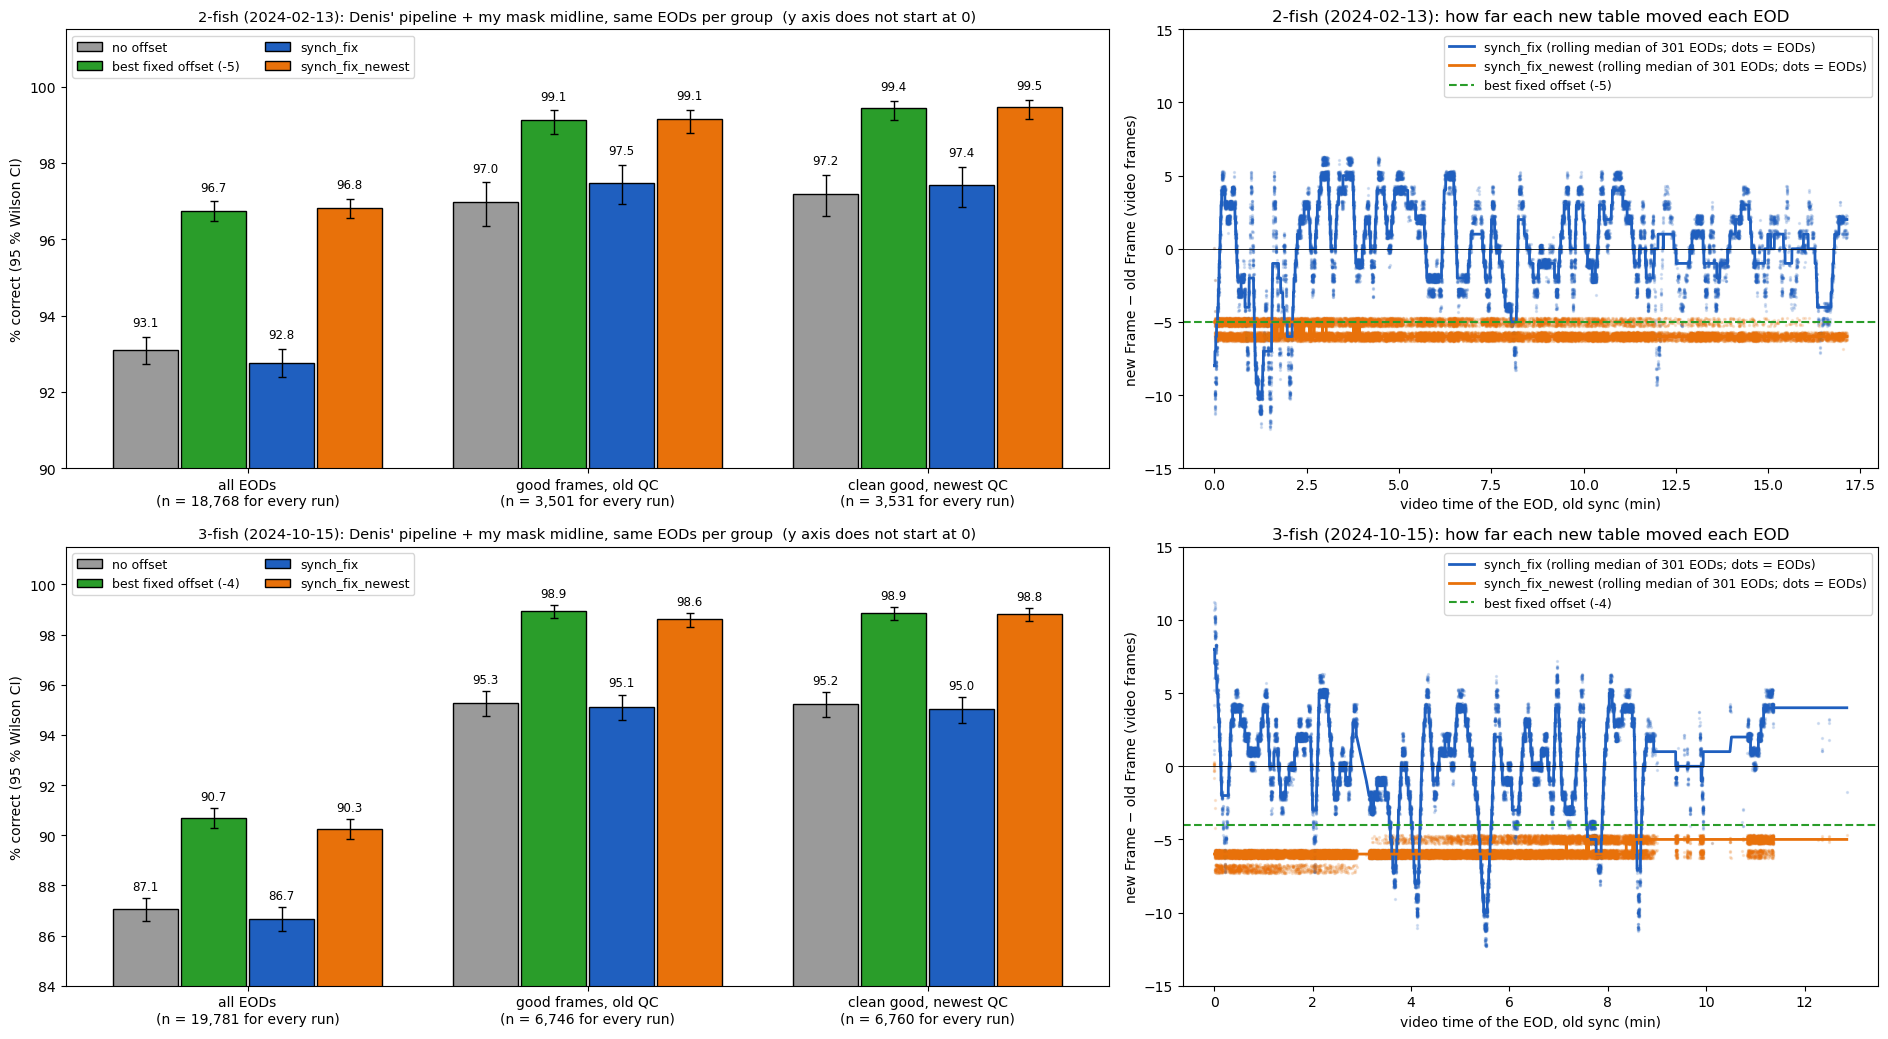

In [4]:
RUN_COL = {'no offset': '#9a9a9a', 'best fixed offset': '#2a9d2a', 'synch_fix': '#1F5FBF', 'synch_fix_newest': '#E8710A'}
fig, ax = plt.subplots(2, 2, figsize=(19, 10.5), gridspec_kw=dict(width_ratios=[1.5, 1]))
for row, (name, x) in enumerate(R.items()):
    A = ax[row, 0]; t = ACC[ACC.recording == x['c']['label']]; runs = list(x['COR']); w = 0.2; grps = list(x['GROUPS'])
    for g, grp in enumerate(grps):
        for i, run in enumerate(runs):
            s = t[(t.run == run) & (t.EODs == grp)].iloc[0]; xx = g + (i - 1.5) * w
            col = RUN_COL['best fixed offset' if run.startswith('best') else run]
            A.bar(xx, s.pct_correct, w * 0.95, color=col, edgecolor='k', label=run if g == 0 else None)
            A.errorbar(xx, s.pct_correct, [[s.pct_correct - s.ci_lo], [s.ci_hi - s.pct_correct]], color='k', capsize=3, lw=1)
            A.text(xx, s.ci_hi + 0.2, f'{s.pct_correct:.1f}', ha='center', va='bottom', fontsize=8.5)
    A.set_ylim(np.floor(t.ci_lo.min() / 2) * 2 - 2, 101.5)
    A.set_xticks(range(len(grps)), [f"{g_}\n(n = {x['GROUPS'][g_].sum():,} for every run)" for g_ in grps])
    A.set_ylabel('% correct (95 % Wilson CI)'); A.set_title(f"{x['c']['label']}: Denis' pipeline + my mask midline, same EODs per group  (y axis does not start at 0)", fontsize=10.5)
    A.legend(loc='upper left', fontsize=9, ncol=2)
    B = ax[row, 1]
    for t_ in NEW:
        f_old, sh = SHIFT[name, t_]; o_ = np.argsort(f_old)
        B.scatter(f_old / FPS / 60, sh + np.random.default_rng(0).uniform(-0.3, 0.3, len(sh)), s=2, color=RUN_COL[t_], alpha=0.15)
        B.plot(f_old[o_] / FPS / 60, pd.Series(sh[o_]).rolling(301, center=True, min_periods=50).median(), color=RUN_COL[t_], lw=2,
               label=f'{t_} (rolling median of 301 EODs; dots = EODs)')
    B.axhline(x['c']['best'], color='#2a9d2a', ls='--', lw=1.5, label=f"best fixed offset ({x['c']['best']:+d})"); B.axhline(0, color='k', lw=0.6)
    B.set_ylim(-15, 15); B.set_xlabel('video time of the EOD, old sync (min)'); B.set_ylabel('new Frame − old Frame (video frames)')
    B.set_title(f"{x['c']['label']}: how far each new table moved each EOD"); B.legend(loc='upper right', fontsize=9)
fig.tight_layout(); fig.savefig('results/baseline_g0/vs_distance/denis_mask_midline_synch_fix_accuracy.png', dpi=100, bbox_inches='tight'); plt.show()

## Figure: no offset, best fixed offset and synch_fix_newest only

Same EODs per group as above; groups: all EODs, and clean good by the newest-frame QC. Right: how far the newest table moved
each EOD's frame relative to the old table.

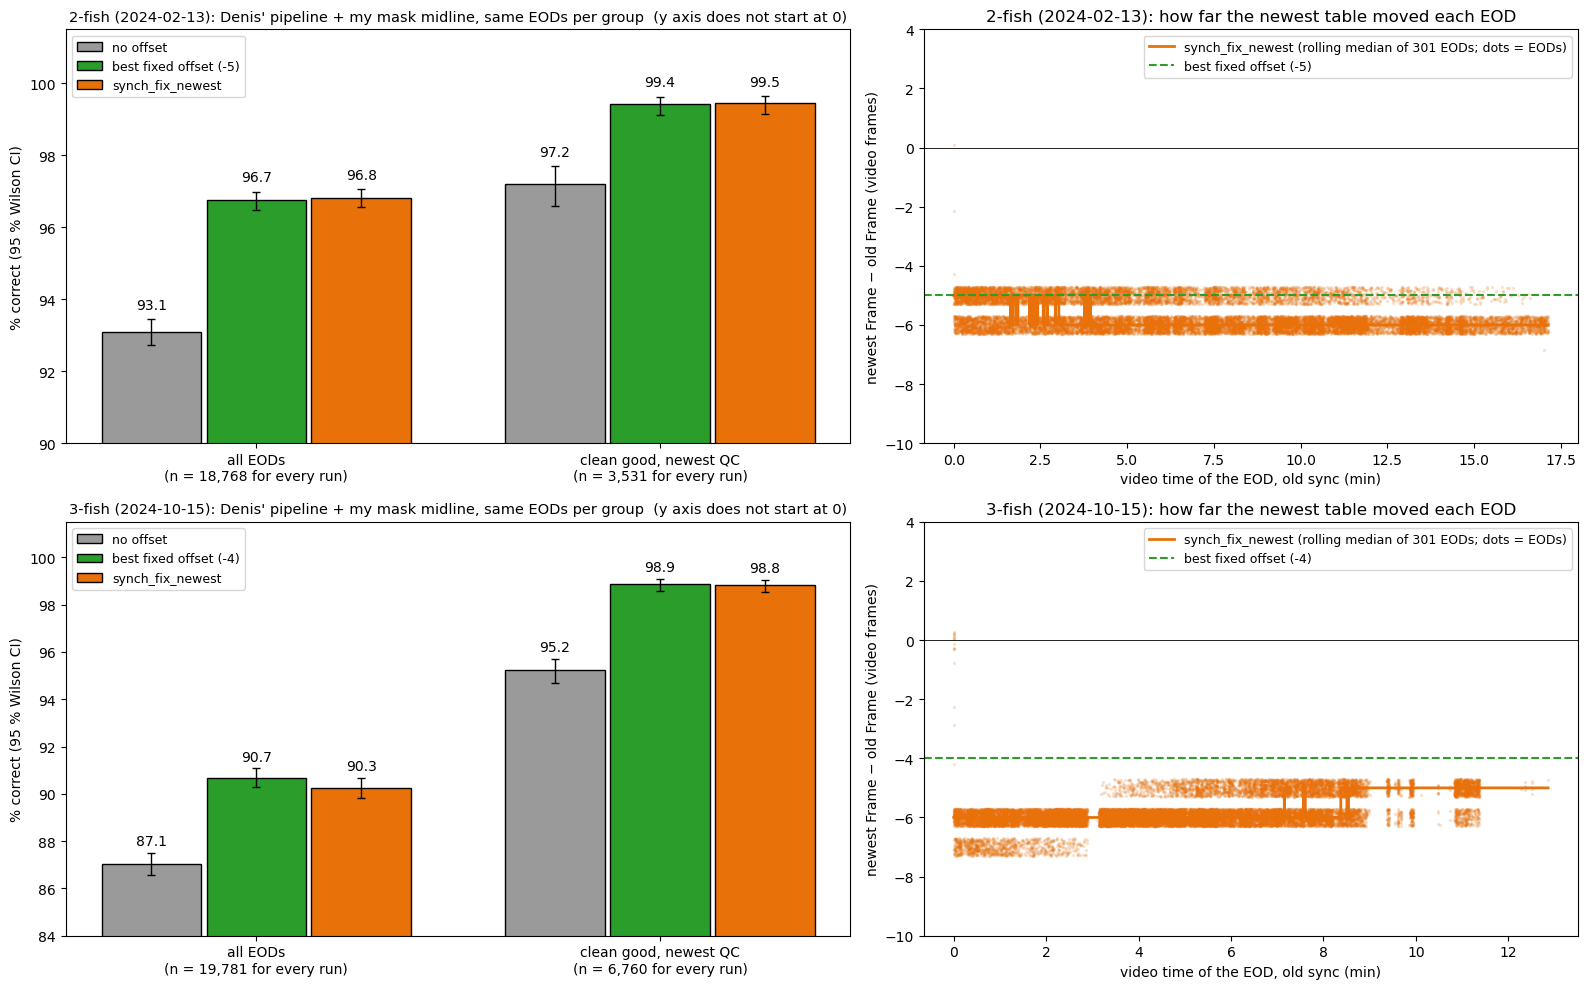

In [5]:
RUNS3 = lambda x: [r for r in x['COR'] if r != 'synch_fix']
GRPS2 = ['all EODs', 'clean good, newest QC']
fig, ax = plt.subplots(2, 2, figsize=(16, 10), gridspec_kw=dict(width_ratios=[1.2, 1]))
for row, (name, x) in enumerate(R.items()):
    A = ax[row, 0]; t = ACC[ACC.recording == x['c']['label']]; runs = RUNS3(x); w = 0.26
    for g, grp in enumerate(GRPS2):
        for i, run in enumerate(runs):
            s = t[(t.run == run) & (t.EODs == grp)].iloc[0]; xx = g + (i - 1) * w
            A.bar(xx, s.pct_correct, w * 0.95, color=RUN_COL['best fixed offset' if run.startswith('best') else run], edgecolor='k',
                  label=run if g == 0 else None)
            A.errorbar(xx, s.pct_correct, [[s.pct_correct - s.ci_lo], [s.ci_hi - s.pct_correct]], color='k', capsize=3, lw=1)
            A.text(xx, s.ci_hi + 0.2, f'{s.pct_correct:.1f}', ha='center', va='bottom', fontsize=10)
    lo = t[t.run.isin(runs) & t.EODs.isin(GRPS2)].ci_lo.min()
    A.set_ylim(np.floor(lo / 2) * 2 - 2, 101.5)
    A.set_xticks(range(len(GRPS2)), [f"{g_}\n(n = {x['GROUPS'][g_].sum():,} for every run)" for g_ in GRPS2])
    A.set_ylabel('% correct (95 % Wilson CI)')
    A.set_title(f"{x['c']['label']}: Denis' pipeline + my mask midline, same EODs per group  (y axis does not start at 0)", fontsize=10.5)
    A.legend(loc='upper left', fontsize=9)
    B = ax[row, 1]; f_old, sh = SHIFT[name, 'synch_fix_newest']; o_ = np.argsort(f_old)
    B.scatter(f_old / FPS / 60, sh + np.random.default_rng(0).uniform(-0.3, 0.3, len(sh)), s=2, color=RUN_COL['synch_fix_newest'], alpha=0.15)
    B.plot(f_old[o_] / FPS / 60, pd.Series(sh[o_]).rolling(301, center=True, min_periods=50).median(), color=RUN_COL['synch_fix_newest'], lw=2,
           label='synch_fix_newest (rolling median of 301 EODs; dots = EODs)')
    B.axhline(x['c']['best'], color='#2a9d2a', ls='--', lw=1.5, label=f"best fixed offset ({x['c']['best']:+d})"); B.axhline(0, color='k', lw=0.6)
    B.set_ylim(-10, 4); B.set_xlabel('video time of the EOD, old sync (min)'); B.set_ylabel('newest Frame − old Frame (video frames)')
    B.set_title(f"{x['c']['label']}: how far the newest table moved each EOD"); B.legend(loc='upper right', fontsize=9)
fig.tight_layout(); fig.savefig('results/baseline_g0/vs_distance/denis_mask_midline_newest_accuracy.png', dpi=100, bbox_inches='tight'); plt.show()